# Lesson 4.3: The Central Limit Theorem

Show that sample means from a very skewed population become more symmetric and bell-shaped as the sample size grows from 1 to 5 to 30.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

## The question

A clinic manager knows waiting times are very skewed: mean 10 minutes, SD 10, most people wait briefly and a few wait very long. An audit of 40 patients found a mean wait of 12 minutes. Is 12 unusual, and can we use a bell curve at all for averages of skewed data?

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## Step 1: A skewed population

Waiting times in a clinic: exponential, with a mean of 10 minutes and an SD of 10. Lots of short waits and a long tail of rare long ones, so it is clearly skewed to the right.

In [1]:
import numpy as np  # Load NumPy for arithmetic and random numbers.
import matplotlib.pyplot as plt  # Load matplotlib; we draw histograms in a later step.
from scipy import stats  # Load SciPy's stats tools, which include skewness and the normal distribution.

rng = np.random.default_rng(99)  # Create a seeded random generator (seed 99) so the results are repeatable.

def sample_means(n, reps=5000):  # Define a helper function that takes a sample size n (and a number of repeats) and returns the sample means.
    return rng.exponential(10, size=(reps, n)).mean(axis=1)  # Inside it, draw reps samples of n exponential waits (mean 10) and average each row; return gives that list back.

single = rng.exponential(10, size=5000)  # Draw 5,000 single waits (n = 1) so we can look at the raw skewed shape.
print(f'skewness of single waits = {stats.skew(single):.2f}')  # Print the skewness of single waits; skewness is 0 for a symmetric shape and positive when there is a long right tail.

skewness of single waits = 1.89


**What this means.** The skewness of single waiting times is 1.89, far above 0. Individual waits are strongly skewed to the right: many short waits and a few very long ones. That is why a bell curve cannot describe a single wait.

## Step 2: Skewness of the sample means

Skewness is 0 for a perfectly symmetric shape. For each n we take 5,000 sample means and measure their skewness. It falls towards 0 roughly like 2 divided by the square root of n.

In [2]:
print('  n   skewness of means   2/sqrt(n)')  # Print column headings for the table.
for n in (1, 5, 30):  # Loop over three sample sizes: single waits, means of 5, and means of 30.
    m = sample_means(n)  # Use the helper to get 5,000 sample means of size n.
    print(f'{n:3d}   {stats.skew(m):15.2f}   {2 / np.sqrt(n):9.2f}')  # Print n, the skewness of those means, and the rough rule 2/sqrt(n) for comparison.

  n   skewness of means   2/sqrt(n)
  1              1.93        2.00
  5              0.85        0.89
 30              0.33        0.37


**What this means.** Skewness falls as n grows: 1.93 for n = 1, 0.85 for n = 5, and 0.33 for n = 30, close to the rule of thumb 2/sqrt(n) (2.00, 0.89, 0.37). Averaging more readings makes the distribution of means more and more symmetric.

## Step 3: Three histograms

The same story as a picture. With n = 1 we see the skewed population itself. With n = 5 the shape is already more balanced, and with n = 30 it looks close to a bell.

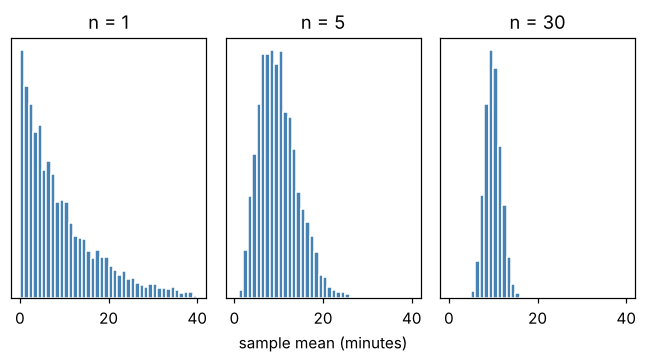

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(6, 3.4), sharex=True)  # Make a row of three small plots that share the same x-axis, so the shapes are directly comparable.
for ax, n in zip(axes, (1, 5, 30)):  # Loop over each plot together with its sample size.
    ax.hist(sample_means(n), bins=np.linspace(0, 40, 41), color='steelblue', edgecolor='white')  # Draw a histogram of 5,000 sample means, 40 equal-width bars from 0 to 40 minutes.
    ax.set_title(f'n = {n}')  # Title each plot with its n.
    ax.set_yticks([])  # Hide the vertical tick labels; only the shape matters here.
axes[1].set_xlabel('sample mean (minutes)')  # Label the shared horizontal axis once, on the middle plot.
plt.tight_layout()  # Tidy the spacing so labels do not overlap.
plt.show()  # Display the figure.

**What this means.** With n = 1 the histogram is the skewed pile of raw waits. With n = 5 it is more balanced but still leans right. With n = 30 it is close to a symmetric bell centred near 10 minutes. This is the Central Limit Theorem in action.

## Step 4: Use the bell curve

The lesson's clinic question: for n = 40 patients, how often does the mean wait reach 12 minutes or more? The CLT lets us use a normal curve with mean 10 and SE = 10 divided by the square root of 40.

In [4]:
se = 10 / np.sqrt(40)  # Standard error for 40 patients: SD 10 divided by the square root of 40.
p_clt = stats.norm.sf(12, loc=10, scale=se)  # Use the bell curve: stats.norm.sf gives the chance of a mean at or above 12 with centre 10 and spread equal to the SE.
simulated = (sample_means(40, reps=20000) >= 12).mean()  # Check by brute force: simulate 20,000 audits of 40 patients and count the share with a mean of 12 or more.

print(f'SE = {se:.3f}')  # Print the standard error.
print(f'CLT answer       P(mean >= 12) = {p_clt:.3f}')  # Print the answer from the bell curve.
print(f'simulation (20k) P(mean >= 12) = {simulated:.3f}')  # Print the answer from the simulation.

SE = 1.581
CLT answer       P(mean >= 12) = 0.103
simulation (20k) P(mean >= 12) = 0.110


**What this means.** The standard error is 1.581. The bell curve says the chance that 40 patients average 12 minutes or more is 0.103; the simulation gives 0.110, nearly the same. So an average of 12 happens about 1 time in 10 by chance alone, which is not strong evidence of a real change.

## So, what is the answer?

Single waits are strongly skewed (skewness 1.89), but means of 30 are nearly symmetric (0.33), so the bell curve works for averages. With 40 patients the chance of an average wait of 12 or more is about 0.10 (0.103 by the bell curve, 0.110 by simulation), so 12 minutes is not unusual. Caution: n around 30 is a rule of thumb; very skewed data may need more.

## Now you try

An IT help desk finds that tickets take on average 20 minutes to resolve, with an SD of 20 minutes, and the times are very skewed. A manager looks at a random batch of 36 tickets and wants to know how often such a batch averages 24 minutes or more just by chance.

**Data:** No list needed: model single ticket times as rng.exponential(20, ...) (mean 20, SD 20) with rng = np.random.default_rng(5), and use batches of n = 36.

1. Find the standard error of the mean of 36 tickets.
2. Use the normal curve to find P(mean >= 24).
3. Check by simulating 20,000 batches of 36 tickets.
4. Measure the skewness of the simulated batch means.

*Hint:* SE = SD / sqrt(n); stats.norm.sf(24, loc=20, scale=se) gives the upper tail. For the simulation, draw a (20000, 36) array of exponentials and average each row.

In [ ]:
# Your turn: write your code here


### Solution (try first, then peek)

In [ ]:
import numpy as np
from scipy import stats
rng = np.random.default_rng(5)
se = 20 / np.sqrt(36)
p_clt = stats.norm.sf(24, loc=20, scale=se)
means = rng.exponential(20, size=(20_000, 36)).mean(axis=1)
print(f'SE = {se:.2f}')
print(f'CLT answer P(mean >= 24) = {p_clt:.3f}')
print(f'simulation P(mean >= 24) = {(means >= 24).mean():.3f}')
print(f'skewness of the means = {stats.skew(means):.2f}')

SE = 3.33
CLT answer P(mean >= 24) = 0.115
simulation P(mean >= 24) = 0.120
skewness of the means = 0.34


**Answer.** The standard error is 3.33 minutes. The normal curve gives P(mean >= 24) = 0.115 and the simulation gives 0.120, so about 1 batch in 9 would average 24 minutes or more by chance. The batch means have skewness 0.34, far less than the very skewed single tickets, which is why the bell curve works.

## The same question in R, SPSS and Stata

**R**

```r
skew <- function(x) mean((x - mean(x))^3) / mean((x - mean(x))^2)^1.5  # Define a skewness function using the same formula SciPy uses, since base R has none.
set.seed(99)  # Fix the random seed so the run can be repeated.
for (n in c(1, 5, 30)) print(skew(replicate(5000, mean(rexp(n, rate = 1/10)))))  # For n = 1, 5 and 30, simulate 5,000 sample means of exponential waits (mean 10) and print their skewness.
pnorm(12, mean = 10, sd = 10 / sqrt(40), lower.tail = FALSE)  # Compute the chance of a mean at or above 12 using the normal curve (lower.tail = FALSE means the upper tail).
```

How to read it: The loop prints three skewness values near 1.9, 0.9 and 0.35, falling as n grows (Python: 1.93, 0.85, 0.33). The pnorm line prints 0.1029, the chance that a mean of 40 waits is 12 or more.

**SPSS** (Analyze > Descriptive Statistics > Descriptives > Options > Skewness)

```
SET SEED=99.
INPUT PROGRAM.
LOOP s = 1 TO 5000.
COMPUTE x1 = RV.EXP(1/10).
COMPUTE total = 0.
LOOP i = 1 TO 30.
COMPUTE total = total + RV.EXP(1/10).
END LOOP.
COMPUTE mean30 = total/30.
END CASE.
END LOOP.
END FILE.
END INPUT PROGRAM.
DESCRIPTIVES VARIABLES=x1 mean30 /STATISTICS=MEAN STDDEV SKEWNESS.
```

How to read it: In the Descriptive Statistics table compare the Skewness column: x1 should be around 2 and mean30 much smaller, around 0.4. Both means are near 10. SPSS uses a slightly adjusted skewness formula and its own random numbers.

**Stata**

```
clear
set seed 99
set obs 5000
generate x1 = rexponential(10)
generate mean30 = 0
forvalues i = 1/30 {
    quietly replace mean30 = mean30 + rexponential(10) / 30
}
tabstat x1 mean30, statistics(mean sd skewness)
display 1 - normal((12 - 10) / (10 / sqrt(40)))
```

How to read it: In the tabstat table, skewness of x1 should be around 2 and of mean30 much smaller (about 0.35). Both means are near 10 and the SD of mean30 is near 1.8. The final display shows 0.1029, the normal-curve answer.